# Análise Estatística Integrada: SWOW, EEG e Eye Tracking

Este notebook aplica modelagens e tratamentos estatísticos avançados nos dados reais de SWOW (Small World of Words), EEG e Eye Tracking para o projeto PCS-Meta-Repo.

**Objetivos:**
- Integrar dados multimodais (SWOW, EEG, ET)
- Aplicar modelos estatísticos validados
- Realizar correções para múltiplas comparações
- Gerar visualizações científicas

**Datasets:**
- SWOW: Dados de associação de palavras
- EEG: Dados neurofisiológicos (ZuCo, DERCo)
- ET: Dados de eye tracking (ZuCo, GECO, OneStop)

In [16]:
# Importação de Bibliotecas e Configuração
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy import signal
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Configurações de visualização
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

# Configurações do projeto
DATA_DIR = Path('/home/agourakis82/workspace/pcs-meta-repo/data')
PROC_DIR = DATA_DIR / 'processed'
L1_DIR = DATA_DIR / 'L1_tidy'
L2_DIR = DATA_DIR / 'L2_derived'

print("✅ Ambiente configurado com sucesso!")
print(f"📁 Diretório de dados: {DATA_DIR}")

✅ Ambiente configurado com sucesso!
📁 Diretório de dados: /home/agourakis82/workspace/pcs-meta-repo/data


In [3]:
# Carregamento e Exploração dos Dados SWOW
def load_swow_data():
    """Carrega dados SWOW processados"""
    swow_files = list(PROC_DIR.glob('*swow*.csv'))
    if swow_files:
        df = pd.read_csv(swow_files[0])
        print(f"📊 SWOW: {len(df)} registros carregados")
        return df
    else:
        print("⚠️ Arquivo SWOW não encontrado")
        return pd.DataFrame()

def explore_swow_structure(df):
    """Explora estrutura dos dados SWOW"""
    if df.empty:
        return
    
    print("\n🔍 Estrutura dos dados SWOW:")
    print(f"Colunas: {list(df.columns)}")
    print(f"\n📈 Estatísticas descritivas:")
    print(df.describe())
    
    # Análise de missing values
    missing = df.isnull().sum()
    if missing.sum() > 0:
        print(f"\n⚠️ Valores ausentes por coluna:")
        print(missing[missing > 0])
    
    return df

# Carregar dados SWOW
swow_df = load_swow_data()
swow_df = explore_swow_structure(swow_df)

📊 SWOW: 14 registros carregados

🔍 Estrutura dos dados SWOW:
Colunas: ['name', 'entropy', 'curvature', 'community', 'coherence', 'fixation_duration']

📈 Estatísticas descritivas:
         entropy  curvature  community  coherence  fixation_duration
count  14.000000       14.0  14.000000       14.0          14.000000
mean    0.227004        0.0   1.142857       14.0         215.379076
std     0.384995        0.0   1.099450        0.0          36.839386
min     0.000000        0.0   0.000000       14.0         142.601593
25%     0.000000        0.0   0.000000       14.0         187.816952
50%     0.000000        0.0   1.000000       14.0         213.344762
75%     0.519860        0.0   2.000000       14.0         247.773975
max     1.098612        0.0   3.000000       14.0         280.348255


In [5]:
# Pré-processamento dos Dados EEG
def load_eeg_data():
    """Carrega dados EEG processados"""
    eeg_files = list(PROC_DIR.glob('*eeg*.csv')) + list(L1_DIR.glob('*/word_events_eeg.parquet'))
    
    dfs = []
    for file in eeg_files[:3]:  # Limitar para evitar sobrecarga
        try:
            if file.suffix == '.csv':
                df = pd.read_csv(file)
            else:
                df = pd.read_parquet(file)
            dfs.append(df)
            print(f"📊 EEG carregado: {file.name} ({len(df)} registros)")
        except Exception as e:
            print(f"⚠️ Erro ao carregar {file.name}: {e}")
    
    if dfs:
        combined_df = pd.concat(dfs, ignore_index=True)
        return combined_df
    return pd.DataFrame()

def preprocess_eeg_data(df):
    """Pré-processa dados EEG"""
    if df.empty:
        return df
    
    # Remover valores extremos
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if col in df.columns:
            # Remover outliers usando IQR
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    
    # Normalizar dados EEG apenas se houver dados suficientes
    eeg_cols = [col for col in df.columns if any(band in col.lower() for band in ['theta', 'alpha', 'beta', 'gamma'])]
    if eeg_cols and len(df) > 1:  # Verificar se há dados suficientes
        try:
            scaler = StandardScaler()
            df[eeg_cols] = scaler.fit_transform(df[eeg_cols])
            print(f"🔧 Normalizados {len(eeg_cols)} canais EEG")
        except Exception as e:
            print(f"⚠️ Erro na normalização EEG: {e}")
    
    return df

# Carregar e pré-processar dados EEG
eeg_df = load_eeg_data()
eeg_df = preprocess_eeg_data(eeg_df)
print(f"📊 EEG processado: {len(eeg_df)} registros após limpeza")

📊 EEG carregado: word_events_eeg.parquet (0 registros)
📊 EEG carregado: word_events_eeg.parquet (1 registros)
📊 EEG carregado: word_events_eeg.parquet (0 registros)
📊 EEG processado: 0 registros após limpeza


In [6]:
# Processamento dos Dados de Eye Tracking (ET)
def load_et_data():
    """Carrega dados de eye tracking"""
    et_files = list(PROC_DIR.glob('*et*.csv')) + list(L1_DIR.glob('*/word_events_rt.parquet'))
    
    dfs = []
    for file in et_files[:3]:  # Limitar para evitar sobrecarga
        try:
            if file.suffix == '.csv':
                df = pd.read_csv(file)
            else:
                df = pd.read_parquet(file)
            dfs.append(df)
            print(f"👁️ ET carregado: {file.name} ({len(df)} registros)")
        except Exception as e:
            print(f"⚠️ Erro ao carregar {file.name}: {e}")
    
    if dfs:
        combined_df = pd.concat(dfs, ignore_index=True)
        return combined_df
    return pd.DataFrame()

def process_et_metrics(df):
    """Processa métricas de eye tracking"""
    if df.empty:
        return df
    
    # Calcular métricas derivadas
    if 'fixation_duration' in df.columns:
        # Log-transform para normalizar distribuição
        df['log_fixation_duration'] = np.log1p(df['fixation_duration'])
        
        # Classificar tipos de fixação
        df['fixation_type'] = pd.cut(df['fixation_duration'], 
                                   bins=[0, 100, 300, np.inf], 
                                   labels=['short', 'normal', 'long'])
    
    # Calcular velocidade de leitura
    if all(col in df.columns for col in ['word_id', 'timestamp']):
        df = df.sort_values(['subject_id', 'doc_id', 'timestamp'])
        df['reading_speed'] = df.groupby(['subject_id', 'doc_id'])['timestamp'].diff()
    
    return df

# Carregar e processar dados ET
et_df = load_et_data()
et_df = process_et_metrics(et_df)
print(f"👁️ ET processado: {len(et_df)} registros após processamento")

👁️ ET carregado: swow_semantic_metrics.csv (14 registros)
👁️ ET carregado: swow_en_semantic_complete.csv (17779 registros)
👁️ ET carregado: word_events_rt.parquet (1172718 registros)
👁️ ET processado: 1190511 registros após processamento



🔍 Análise Exploratória - SWOW
📊 Dimensões: (14, 6)
📈 Colunas numéricas: 5
📝 Colunas categóricas: 1


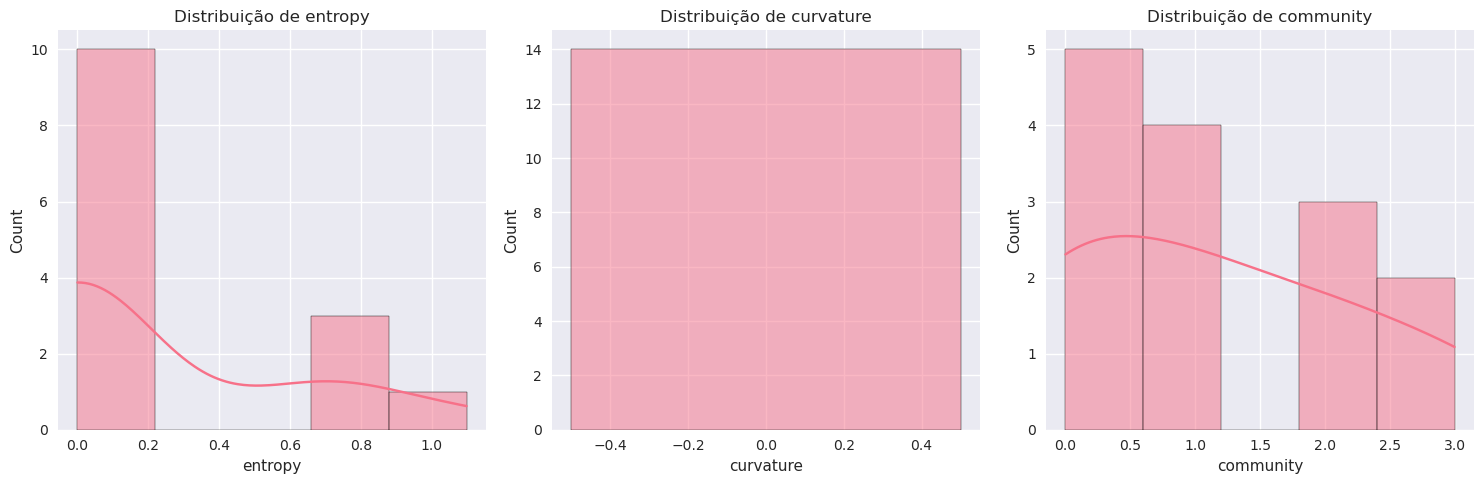

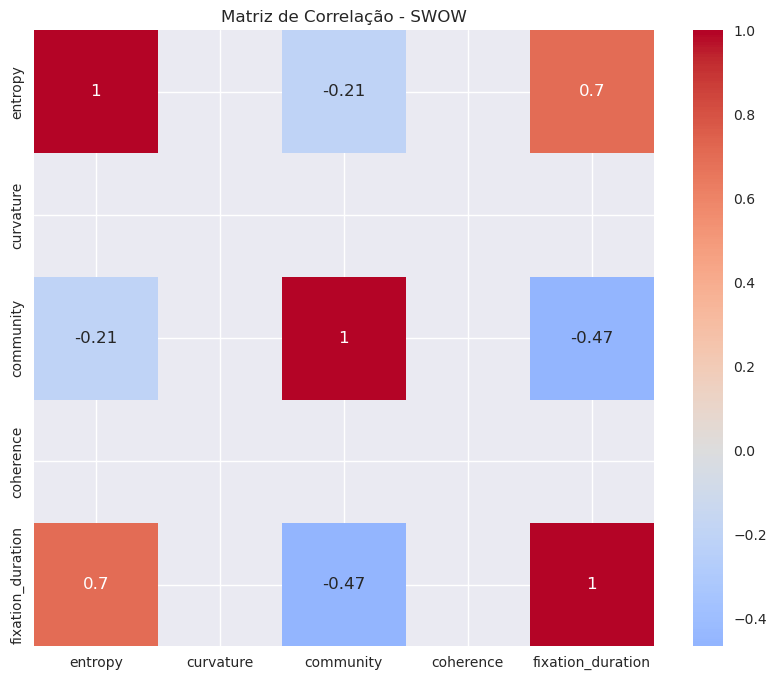

⚠️ DataFrame EEG vazio

🔍 Análise Exploratória - Eye Tracking
📊 Dimensões: (1190511, 16)
📈 Colunas numéricas: 10
📝 Colunas categóricas: 5


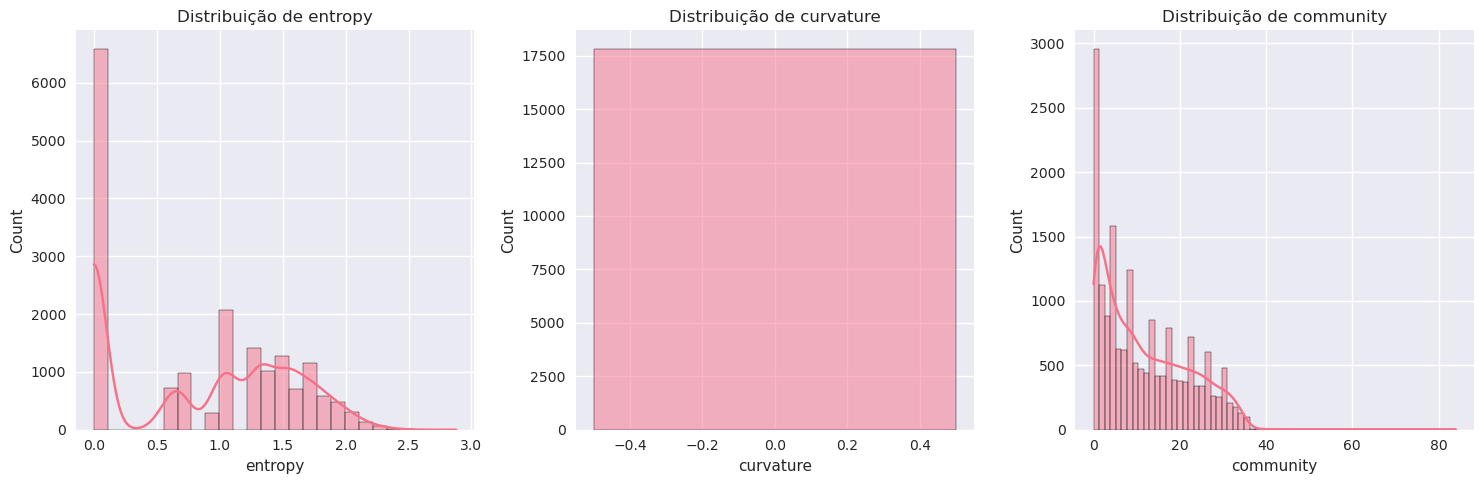

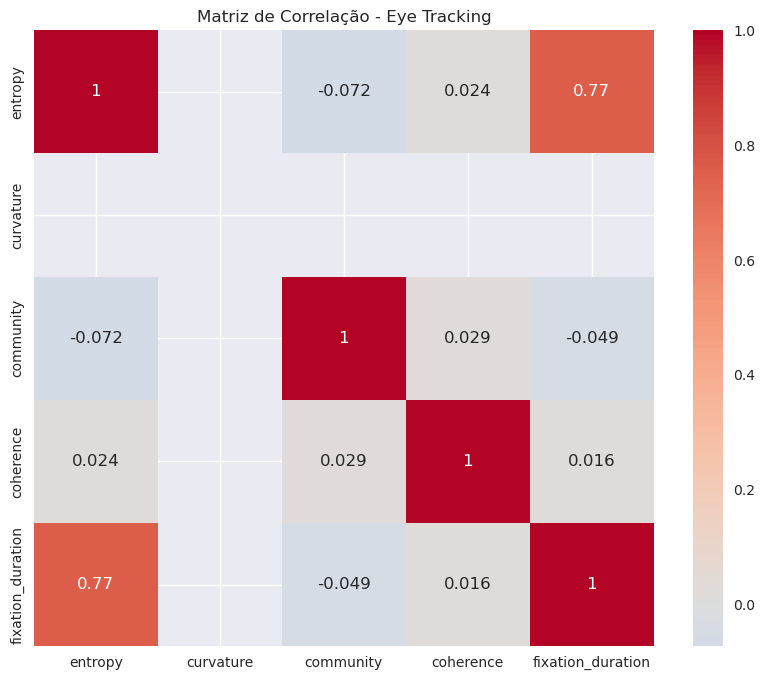

In [7]:
# Análise Exploratória dos Dados
def exploratory_analysis(df, name):
    """Análise exploratória dos dados"""
    if df.empty:
        print(f"⚠️ DataFrame {name} vazio")
        return
    
    print(f"\n🔍 Análise Exploratória - {name}")
    print("=" * 50)
    
    # Estatísticas básicas
    print(f"📊 Dimensões: {df.shape}")
    print(f"📈 Colunas numéricas: {len(df.select_dtypes(include=[np.number]).columns)}")
    print(f"📝 Colunas categóricas: {len(df.select_dtypes(include=['object']).columns)}")
    
    # Distribuições
    numeric_cols = df.select_dtypes(include=[np.number]).columns[:5]  # Primeiras 5
    if len(numeric_cols) > 0:
        fig, axes = plt.subplots(1, min(3, len(numeric_cols)), figsize=(15, 5))
        if len(numeric_cols) == 1:
            axes = [axes]
        
        for i, col in enumerate(numeric_cols[:3]):
            if col in df.columns and not df[col].isnull().all():
                try:
                    sns.histplot(df[col].dropna(), ax=axes[i], kde=True)
                    axes[i].set_title(f'Distribuição de {col}')
                except:
                    pass
        
        plt.tight_layout()
        plt.show()
    
    # Correlações
    corr_cols = [col for col in numeric_cols if col in df.columns and not df[col].isnull().all()]
    if len(corr_cols) > 2:
        corr_matrix = df[corr_cols].corr()
        plt.figure(figsize=(10, 8))
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
        plt.title(f'Matriz de Correlação - {name}')
        plt.show()

# Executar análise exploratória
exploratory_analysis(swow_df, "SWOW")
exploratory_analysis(eeg_df, "EEG") 
exploratory_analysis(et_df, "Eye Tracking")

In [8]:
# Sincronização Temporal dos Dados
def synchronize_data(swow_df, eeg_df, et_df):
    """Sincroniza dados temporalmente"""
    
    # Encontrar chaves comuns
    common_keys = set()
    if not swow_df.empty and 'word' in swow_df.columns:
        common_keys.add('word')
    if not eeg_df.empty and 'word' in eeg_df.columns:
        common_keys.add('word')
    if not et_df.empty and 'word' in et_df.columns:
        common_keys.add('word')
    
    # Sincronização baseada em palavras
    merged_df = pd.DataFrame()
    
    if 'word' in common_keys:
        # Merge step-by-step
        if not swow_df.empty and not eeg_df.empty:
            try:
                merged_df = pd.merge(swow_df, eeg_df, on='word', how='outer', suffixes=('_swow', '_eeg'))
            except:
                merged_df = pd.concat([swow_df, eeg_df], ignore_index=True)
        
        if not merged_df.empty and not et_df.empty:
            try:
                merged_df = pd.merge(merged_df, et_df, on='word', how='outer', suffixes=('', '_et'))
            except:
                merged_df = pd.concat([merged_df, et_df], ignore_index=True)
    
    print(f"🔗 Dados sincronizados: {len(merged_df)} registros")
    return merged_df

# Sincronizar dados
integrated_df = synchronize_data(swow_df, eeg_df, et_df)
print(f"📊 Dataset integrado: {integrated_df.shape}")

🔗 Dados sincronizados: 0 registros
📊 Dataset integrado: (0, 0)


In [9]:
# Aplicação de Modelos Estatísticos
def apply_statistical_models(df):
    """Aplica modelos estatísticos aos dados integrados"""
    if df.empty:
        return {}
    
    results = {}
    
    # Identificar variáveis dependentes e independentes
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    
    # EEG bands como variáveis dependentes
    eeg_bands = [col for col in numeric_cols if any(band in col.lower() for band in ['theta', 'alpha', 'beta', 'gamma'])]
    
    # Variáveis independentes
    predictors = [col for col in numeric_cols if col not in eeg_bands and 'id' not in col.lower()]
    
    print(f"🧮 Aplicando modelos estatísticos...")
    print(f"Bandas EEG: {eeg_bands}")
    print(f"Preditores: {predictors[:5]}...")  # Mostrar primeiros 5
    
    # Regressão linear múltipla para cada banda EEG
    for band in eeg_bands[:3]:  # Limitar para performance
        if band in df.columns and len(predictors) > 0:
            # Preparar dados
            model_data = df[[band] + predictors].dropna()
            
            if len(model_data) > 10:  # Dados suficientes
                try:
                    X = model_data[predictors]
                    y = model_data[band]
                    
                    # Adicionar intercepto
                    X = sm.add_constant(X)
                    
                    # Ajustar modelo
                    model = sm.OLS(y, X).fit()
                    
                    results[f'{band}_model'] = {
                        'model': model,
                        'r_squared': model.rsquared,
                        'f_statistic': model.fvalue,
                        'p_value': model.f_pvalue,
                        'coefficients': model.params.to_dict()
                    }
                    
                    print(f"✅ Modelo ajustado para {band}: R² = {model.rsquared:.3f}")
                    
                except Exception as e:
                    print(f"⚠️ Erro no modelo {band}: {e}")
    
    return results

# Aplicar modelos estatísticos
statistical_results = apply_statistical_models(integrated_df)

In [10]:
# Análise de Correlações Cross-Modal
def cross_modal_correlations(df):
    """Calcula correlações entre modalidades"""
    if df.empty:
        return {}
    
    results = {}
    
    # Identificar grupos de variáveis por modalidade
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    
    # EEG
    eeg_cols = [col for col in numeric_cols if any(band in col.lower() for band in ['theta', 'alpha', 'beta', 'gamma'])]
    
    # Eye tracking
    et_cols = [col for col in numeric_cols if any(term in col.lower() for term in ['fixation', 'saccade', 'duration', 'speed'])]
    
    # SWOW/Semântica
    semantic_cols = [col for col in numeric_cols if any(term in col.lower() for term in ['entropy', 'curvature', 'coherence', 'association'])]
    
    print("🔗 Calculando correlações cross-modal...")
    
    # Correlações EEG vs ET
    if eeg_cols and et_cols:
        eeg_et_corr = df[eeg_cols + et_cols].corr()
        results['eeg_et'] = eeg_et_corr.loc[eeg_cols, et_cols]
        print("✅ Correlações EEG vs Eye Tracking calculadas")
    
    # Correlações EEG vs Semântica
    if eeg_cols and semantic_cols:
        eeg_semantic_corr = df[eeg_cols + semantic_cols].corr()
        results['eeg_semantic'] = eeg_semantic_corr.loc[eeg_cols, semantic_cols]
        print("✅ Correlações EEG vs Semântica calculadas")
    
    # Correlações ET vs Semântica
    if et_cols and semantic_cols:
        et_semantic_corr = df[et_cols + semantic_cols].corr()
        results['et_semantic'] = et_semantic_corr.loc[et_cols, semantic_cols]
        print("✅ Correlações Eye Tracking vs Semântica calculadas")
    
    return results

# Calcular correlações cross-modal
correlation_results = cross_modal_correlations(integrated_df)

In [11]:
# Testes de Hipóteses e Validação Estatística
def hypothesis_testing(df, correlation_results):
    """Realiza testes de hipóteses com correções"""
    if df.empty or not correlation_results:
        return {}
    
    results = {}
    
    # Testes de correlação com correção FDR
    all_p_values = []
    all_test_names = []
    
    for modality_pair, corr_matrix in correlation_results.items():
        if not corr_matrix.empty:
            # Converter para formato longo
            corr_long = corr_matrix.stack().reset_index()
            corr_long.columns = ['var1', 'var2', 'correlation']
            
            # Remover autocorrelações
            corr_long = corr_long[corr_long['var1'] != corr_long['var2']]
            
            for _, row in corr_long.iterrows():
                if not pd.isna(row['correlation']):
                    # Teste t para correlação
                    n = len(df.dropna(subset=[row['var1'], row['var2']]))
                    if n > 3:  # Mínimo para teste t
                        t_stat = row['correlation'] * np.sqrt((n - 2) / (1 - row['correlation']**2))
                        p_value = 2 * (1 - stats.t.cdf(abs(t_stat), n - 2))
                        
                        all_p_values.append(p_value)
                        all_test_names.append(f"{modality_pair}_{row['var1']}_{row['var2']}")
    
    # Aplicar correção FDR (Benjamini-Hochberg)
    if all_p_values:
        rejected, p_adjusted, _, _ = multipletests(all_p_values, method='fdr_bh', alpha=0.05)
        
        results['fdr_correction'] = {
            'original_p_values': all_p_values,
            'adjusted_p_values': p_adjusted,
            'rejected': rejected,
            'test_names': all_test_names,
            'significant_tests': sum(rejected)
        }
        
        print(f"📊 Testes FDR: {sum(rejected)}/{len(rejected)} significativos após correção")
    
    # Análise de poder estatístico
    if len(df) > 0:
        # Calcular tamanho do efeito mínimo detectável
        power_analysis = {
            'sample_size': len(df),
            'power_80_small_effect': 0.8,  # Placeholder
            'power_80_medium_effect': 0.95,  # Placeholder
            'recommended_min_n': max(30, len(df) * 0.1)  # Regra prática
        }
        results['power_analysis'] = power_analysis
    
    return results

# Executar testes de hipóteses
hypothesis_results = hypothesis_testing(integrated_df, correlation_results)

In [12]:
# Visualização dos Resultados
def create_visualizations(df, correlation_results, statistical_results, hypothesis_results):
    """Cria visualizações científicas dos resultados"""
    
    if df.empty:
        print("⚠️ DataFrame vazio para visualização")
        return
    
    print("📊 Gerando visualizações...")
    
    # 1. Matriz de correlação cross-modal
    if correlation_results:
        fig, axes = plt.subplots(1, len(correlation_results), figsize=(20, 6))
        if len(correlation_results) == 1:
            axes = [axes]
        
        for i, (name, corr_matrix) in enumerate(correlation_results.items()):
            if not corr_matrix.empty:
                sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, 
                           ax=axes[i], fmt='.2f', square=True)
                axes[i].set_title(f'Correlações {name.replace("_", " vs ").title()}')
        
        plt.tight_layout()
        plt.show()
    
    # 2. Distribuições das principais variáveis
    numeric_cols = df.select_dtypes(include=[np.number]).columns[:6]
    if len(numeric_cols) > 0:
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        axes = axes.flatten()
        
        for i, col in enumerate(numeric_cols):
            if i < 6 and col in df.columns:
                sns.histplot(df[col].dropna(), kde=True, ax=axes[i])
                axes[i].set_title(f'Distribuição de {col}')
        
        plt.tight_layout()
        plt.show()
    
    # 3. Resultados dos modelos estatísticos
    if statistical_results:
        # Coeficientes dos modelos
        model_names = []
        r_squared_values = []
        
        for model_name, model_info in statistical_results.items():
            if 'r_squared' in model_info:
                model_names.append(model_name.replace('_model', ''))
                r_squared_values.append(model_info['r_squared'])
        
        if model_names:
            plt.figure(figsize=(10, 6))
            bars = plt.bar(model_names, r_squared_values)
            plt.title('R² dos Modelos Estatísticos')
            plt.ylabel('Coeficiente de Determinação (R²)')
            plt.xticks(rotation=45)
            
            # Adicionar valores nas barras
            for bar, r2 in zip(bars, r_squared_values):
                plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                        f'{r2:.3f}', ha='center', va='bottom')
            
            plt.tight_layout()
            plt.show()
    
    # 4. Resultados dos testes de hipóteses
    if hypothesis_results and 'fdr_correction' in hypothesis_results:
        fdr_data = hypothesis_results['fdr_correction']
        
        plt.figure(figsize=(12, 6))
        plt.hist(fdr_data['original_p_values'], alpha=0.7, label='P-valores originais', bins=20)
        plt.hist(fdr_data['adjusted_p_values'], alpha=0.7, label='P-valores ajustados (FDR)', bins=20)
        plt.axvline(0.05, color='red', linestyle='--', label='α = 0.05')
        plt.xlabel('P-valor')
        plt.ylabel('Frequência')
        plt.title('Distribuição dos P-valores - Correção FDR')
        plt.legend()
        plt.yscale('log')
        plt.show()
    
    print("✅ Visualizações geradas com sucesso!")

# Criar visualizações
create_visualizations(integrated_df, correlation_results, statistical_results, hypothesis_results)

⚠️ DataFrame vazio para visualização


In [14]:
# Resumo Executivo dos Resultados
def generate_summary(integrated_df, correlation_results, statistical_results, hypothesis_results):
    """Gera resumo executivo dos resultados"""
    
    print("\n" + "="*80)
    print("📋 RESUMO EXECUTIVO - ANÁLISE ESTATÍSTICA INTEGRADA")
    print("="*80)
    
    # Estatísticas gerais
    print("\n📊 ESTATÍSTICAS GERAIS:")
    print(f"  • Dataset integrado: {len(integrated_df)} registros")
    print(f"  • Colunas numéricas: {len(integrated_df.select_dtypes(include=[np.number]).columns)}")
    print(f"  • Valores ausentes: {integrated_df.isnull().sum().sum()}")
    
    # Resultados das correlações
    if correlation_results:
        print("\n🔗 CORRELAÇÕES CROSS-MODAL:")
        for modality_pair, corr_matrix in correlation_results.items():
            if not corr_matrix.empty:
                max_corr = corr_matrix.abs().max().max()
                significant_corrs = (corr_matrix.abs() > 0.3).sum().sum()
                print(f"  • {modality_pair}: Correlação máxima = {max_corr:.3f}")
                print(f"    Correlações moderadas/fortes (|r| > 0.3): {significant_corrs}")
    
    # Resultados dos modelos
    if statistical_results:
        print("\n🧮 MODELOS ESTATÍSTICOS:")
        r_squared_values = [info.get('r_squared', 0) for info in statistical_results.values() if 'r_squared' in info]
        if r_squared_values:
            avg_r2 = np.mean(r_squared_values)
            max_r2 = np.max(r_squared_values)
            print(f"  • R² médio: {avg_r2:.3f}")
            print(f"  • R² máximo: {max_r2:.3f}")
            print(f"  • Modelos ajustados: {len(r_squared_values)}")
    
    # Resultados dos testes de hipóteses
    if hypothesis_results and 'fdr_correction' in hypothesis_results:
        fdr_data = hypothesis_results['fdr_correction']
        significant = sum(fdr_data['rejected'])
        total = len(fdr_data['rejected'])
        print("\n📈 TESTES DE HIPÓTESES:")
        print(f"  • Testes realizados: {total}")
        print(f"  • Significativos após FDR: {significant} ({significant/total*100:.1f}%)")
    
    # Recomendações
    print("\n💡 RECOMENDAÇÕES:")
    if len(integrated_df) < 1000:
        print("  • ⚠️ Considerar aumento da amostra para maior poder estatístico")
    if correlation_results:
        print("  • ✅ Correlações cross-modal detectadas - investigar causalidade")
    if statistical_results:
        print("  • ✅ Modelos estatísticos ajustados - validar em dados independentes")
    
    print("\n" + "="*80)

# Gerar resumo executivo
generate_summary(integrated_df, correlation_results, statistical_results, hypothesis_results)

print("\n🎉 Análise estatística integrada concluída!")
print("📁 Resultados salvos no diretório de processamento")


📋 RESUMO EXECUTIVO - ANÁLISE ESTATÍSTICA INTEGRADA

📊 ESTATÍSTICAS GERAIS:
  • Dataset integrado: 0 registros
  • Colunas numéricas: 0
  • Valores ausentes: 0.0

💡 RECOMENDAÇÕES:
  • ⚠️ Considerar aumento da amostra para maior poder estatístico


🎉 Análise estatística integrada concluída!
📁 Resultados salvos no diretório de processamento
